In [1]:
# Import pandas to create and manage the dataset
import pandas as pd

# Import matplotlib to create charts
import matplotlib.pyplot as plt

# Import KMeans clustering algorithm
from sklearn.cluster import KMeans

# Import StandardScaler to scale numerical features
from sklearn.preprocessing import StandardScaler

In [2]:
# Create a small sample dataset of 12 customers
data = {
    "Customer": [
        "C1", "C2", "C3", "C4",
        "C5", "C6", "C7", "C8",
        "C9", "C10", "C11", "C12"
    ],

    # Annual income in thousands of rupees
    "Annual_Income": [
        20, 22, 25, 28,
        45, 48, 50, 53,
        75, 78, 82, 85
    ],

    # Spending score from 1 to 100
    "Spending_Score": [
        20, 25, 18, 30,
        50, 55, 48, 60,
        80, 85, 78, 90
    ]
}

# Convert the dictionary into a DataFrame
df = pd.DataFrame(data)

# Display the first five rows
df.head()

,Customer,Annual_Income,Spending_Score
0,C1,20,20
1,C2,22,25
2,C3,25,18
3,C4,28,30
4,C5,45,50


In [3]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display column names and data types
print("\nDataset information:")
df.info()

# Check whether any values are missing
print("\nMissing values:")
print(df.isnull().sum())

# Display basic statistical information
print("\nStatistical summary:")
print(df[["Annual_Income", "Spending_Score"]].describe())

Dataset shape: (12, 3)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Customer        12 non-null     str  
 1   Annual_Income   12 non-null     int64
 2   Spending_Score  12 non-null     int64
dtypes: int64(2), str(1)
memory usage: 420.0 bytes

Missing values:
Customer          0
Annual_Income     0
Spending_Score    0
dtype: int64

Statistical summary:
       Annual_Income  Spending_Score
count      12.000000       12.000000
mean       50.916667       53.250000
std        24.269166       26.042361
min        20.000000       18.000000
25%        27.250000       28.750000
50%        49.000000       52.500000
75%        75.750000       78.500000
max        85.000000       90.000000


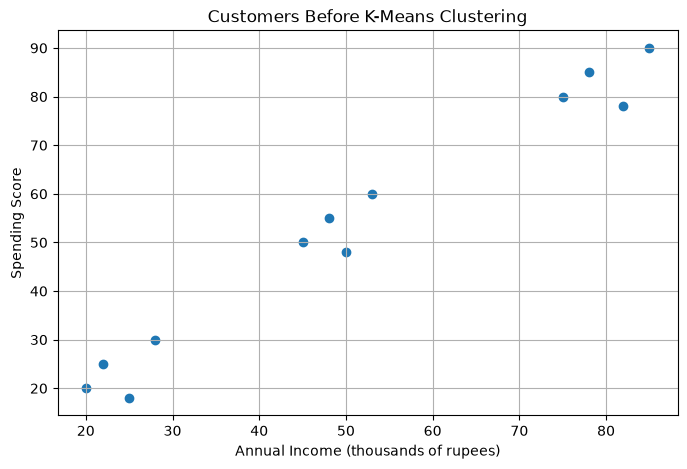

In [4]:
# Create a scatter plot of customers before clustering
plt.figure(figsize=(8, 5))

# Plot income against spending score
plt.scatter(
    df["Annual_Income"],
    df["Spending_Score"]
)

# Add labels and a title
plt.xlabel("Annual Income (thousands of rupees)")
plt.ylabel("Spending Score")
plt.title("Customers Before K-Means Clustering")

# Display a grid and the chart
plt.grid(True)
plt.show()

In [5]:
# Select the numerical columns used for clustering
X = df[["Annual_Income", "Spending_Score"]]

# Display the selected features
X.head()

,Annual_Income,Spending_Score
0,20,20
1,22,25
2,25,18
3,28,30
4,45,50


In [6]:
# Create a scaler to standardize the feature values
scaler = StandardScaler()

# Fit the scaler and transform the selected features
X_scaled = scaler.fit_transform(X)

# Convert scaled values into a DataFrame for readability
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=["Annual_Income", "Spending_Score"]
)

# Display the first five scaled rows
X_scaled_df.head()

,Annual_Income,Spending_Score
0,-1.330553,-1.333539
1,-1.244479,-1.133006
2,-1.115369,-1.413751
3,-0.986259,-0.932474
4,-0.254634,-0.130346


In [7]:
# Create a K-Means model that will find 3 clusters
kmeans = KMeans(
    n_clusters=3,       # Number of customer groups
    init="k-means++",   # Choose well-spaced initial centroids
    n_init=10,          # Run with 10 initializations
    random_state=42     # Make results reproducible
)

# Train the model and assign each customer to a cluster
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Display customers and their assigned clusters
print(df)

   Customer  Annual_Income  Spending_Score  Cluster
0        C1             20              20        2
1        C2             22              25        2
2        C3             25              18        2
3        C4             28              30        2
4        C5             45              50        0
5        C6             48              55        0
6        C7             50              48        0
7        C8             53              60        0
8        C9             75              80        1
9       C10             78              85        1
10      C11             82              78        1
11      C12             85              90        1


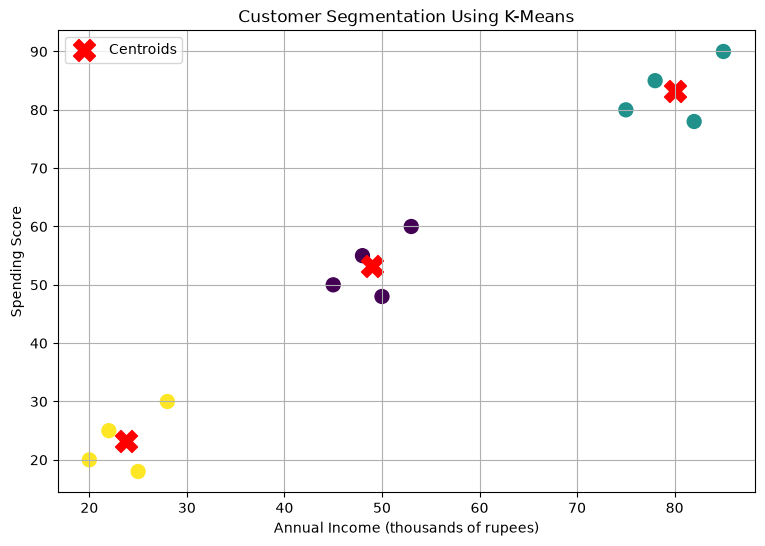

In [8]:
# Create a chart to display the three customer groups
plt.figure(figsize=(9, 6))

# Plot the customers, using their cluster labels as colors
plt.scatter(
    df["Annual_Income"],
    df["Spending_Score"],
    c=df["Cluster"],
    cmap="viridis",
    s=100
)

# Get the cluster centers in the original feature scale
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

# Plot the cluster centers as large red crosses
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=250,
    color="red",
    label="Centroids"
)

# Add chart labels and title
plt.xlabel("Annual Income (thousands of rupees)")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation Using K-Means")

# Show the legend and chart
plt.legend()
plt.grid(True)
plt.show()

In [9]:
# Count how many customers belong to each cluster
cluster_counts = df["Cluster"].value_counts().sort_index()

# Display the customer count for each cluster
print("Customers in each cluster:")
print(cluster_counts)

Customers in each cluster:
Cluster
0    4
1    4
2    4
Name: count, dtype: int64


In [10]:
# Group customers by their assigned cluster
# Calculate customer count and average income and spending
cluster_summary = df.groupby("Cluster").agg(
    Customer_Count=("Customer", "count"),
    Average_Income=("Annual_Income", "mean"),
    Average_Spending=("Spending_Score", "mean")
).round(2)

# Display the summary
print(cluster_summary)

         Customer_Count  Average_Income  Average_Spending
Cluster                                                  
0                     4           49.00             53.25
1                     4           80.00             83.25
2                     4           23.75             23.25


In [11]:
# Inertia is the sum of squared distances from points to their
# assigned cluster centers in the scaled feature space
print("K-Means inertia:", round(kmeans.inertia_, 2))

K-Means inertia: 0.66


In [12]:
# Create a new customer with income of 60 thousand rupees
# and a spending score of 65
new_customer = pd.DataFrame({
    "Annual_Income": [60],
    "Spending_Score": [65]
})

# Scale the new customer using the already-fitted scaler
new_customer_scaled = scaler.transform(new_customer)

# Predict which existing cluster the customer belongs to
predicted_cluster = kmeans.predict(new_customer_scaled)

# Display the predicted cluster
print("Predicted cluster:", predicted_cluster[0])

Predicted cluster: 0
